# 07 · Interconnection queues (Prompt 12)

Source: Lawrence Berkeley National Laboratory and GridTracker, *Queued Up: 2026 Edition* (data through the end of 2025), CC BY 4.0.
Built by `python -m glg.ingest.queues` and `python -m glg.models.queue_summary`. Active = still in the queue at the end of 2025
(suspended requests excluded). Hybrids count all their components. **Queue MW is a ceiling, not a forecast**: most requests are withdrawn.

In [1]:
import polars as pl, matplotlib.pyplot as plt, numpy as np
from matplotlib.patches import Patch
from glg.config import FIGURES_DIR
from glg.models import queue_summary as qs
pl.Config(tbl_rows=40, tbl_cols=16, tbl_width_chars=230)
active = pl.read_csv(qs.ACTIVE_PATH); by_year = pl.read_csv(qs.ACTIVE_YEAR_PATH)
comp = pl.read_csv(qs.COMPLETION_PATH); timing = pl.read_csv(qs.TIMING_PATH)

## Active queue by region × technology (GW)

In [2]:
active.with_columns(pl.col(pl.Float64).round(1))

level,unit,solar_gw,wind_gw,battery_gw,hybrid_gw,gas_gw,nuclear_gw,other_gw,total_gw,n_active
str,str,f64,f64,f64,f64,f64,f64,f64,f64,i64
"""region""","""West""",31.7,49.9,71.7,238.4,21.4,2.9,32.5,448.6,1603
"""region""","""ERCOT""",82.7,42.6,120.9,115.6,44.2,0.0,1.8,408.0,1796
"""region""","""MISO""",133.2,42.7,55.0,48.5,65.3,2.2,3.3,350.1,1646
"""region""","""CAISO""",6.4,3.9,48.6,131.1,0.7,0.0,0.1,190.7,432
"""region""","""SPP""",37.0,26.7,30.8,20.4,33.1,0.0,3.1,151.2,683
"""region""","""Southeast""",43.5,2.6,17.4,10.0,62.6,3.7,4.0,143.8,957
"""region""","""PJM""",54.1,19.3,29.0,13.7,12.7,1.6,0.2,130.6,1134
"""region""","""NYISO""",6.6,7.3,11.1,2.1,0.0,0.0,0.0,27.1,190
"""region""","""ISO-NE""",1.4,6.0,6.9,0.2,0.0,0.0,0.0,14.6,72


## Completion: requests that entered in 2000–2020, and time to operation (projects online 2018–2025)

In [3]:
comp.filter(pl.col('type_group').is_null()).select('level', 'unit', 'n', 'pct_n_operational', 'pct_mw_operational', 'pct_mw_withdrawn',
    'pct_mw_active', 'pct_mw_suspended').join(timing, on=['level', 'unit'], how='left').with_columns(pl.col(pl.Float64).round(1))

level,unit,n,pct_n_operational,pct_mw_operational,pct_mw_withdrawn,pct_mw_active,pct_mw_suspended,n_online,median_years_ir_to_cod,median_years_ir_to_ia,n_with_ia_date
str,str,i64,f64,f64,f64,f64,f64,i64,f64,f64,i64
"""region""","""CAISO""",1910,12.2,8.2,76.4,15.4,0.0,96,7.8,4.3,87
"""region""","""ERCOT""",1553,29.6,24.4,57.2,14.9,3.5,376,3.8,1.5,319
"""region""","""ISO-NE""",827,26.8,17.6,76.5,5.8,0.0,null,null,null,null
"""region""","""MISO""",2806,18.1,14.0,75.1,10.9,0.0,147,4.2,2.8,139
"""region""","""NYISO""",1035,19.4,12.0,81.3,6.7,0.0,32,5.0,3.2,26
"""region""","""PJM""",5589,20.5,13.3,77.8,7.4,1.6,427,4.9,3.3,83
"""region""","""SPP""",1682,16.5,13.8,75.5,10.3,0.4,108,4.8,null,0
"""region""","""Southeast""",2072,15.8,11.2,82.6,5.8,0.3,189,4.0,1.3,13
"""region""","""West""",4874,16.9,8.8,75.0,12.9,3.3,64,3.2,2.3,26


## Completion by technology (ISO/RTO and non-ISO regions pooled)

In [4]:
c = comp.filter((pl.col('level') == 'region') & pl.col('type_group').is_not_null())
c.group_by('type_group').agg(pl.col('n').sum(), (pl.col('pct_mw_operational') * pl.col('mw')).sum() / pl.col('mw').sum()).sort('type_group')

type_group,n,pct_mw_operational
str,i64,f64
"""Battery""",1492,7.312772
"""Gas""",2677,16.927178
"""Hybrid""",1526,8.940897
"""Nuclear""",163,18.309602
"""Other""",2326,11.003714
"""Solar""",8616,10.588055
"""Wind""",5548,13.741584


## Chart 5: queue backlog by technology and queue-entry year

Active requests at the end of 2025, by the year they entered the queue. Shared y-axis, so panel heights compare directly.

2026-11-08 17:50:08,874 INFO chart5_queue_backlog (light): chart5_queue_backlog.png, chart5_queue_backlog.svg


2026-11-08 17:50:09,483 INFO chart5_queue_backlog (dark): chart5_queue_backlog_dark.png, chart5_queue_backlog_dark.svg


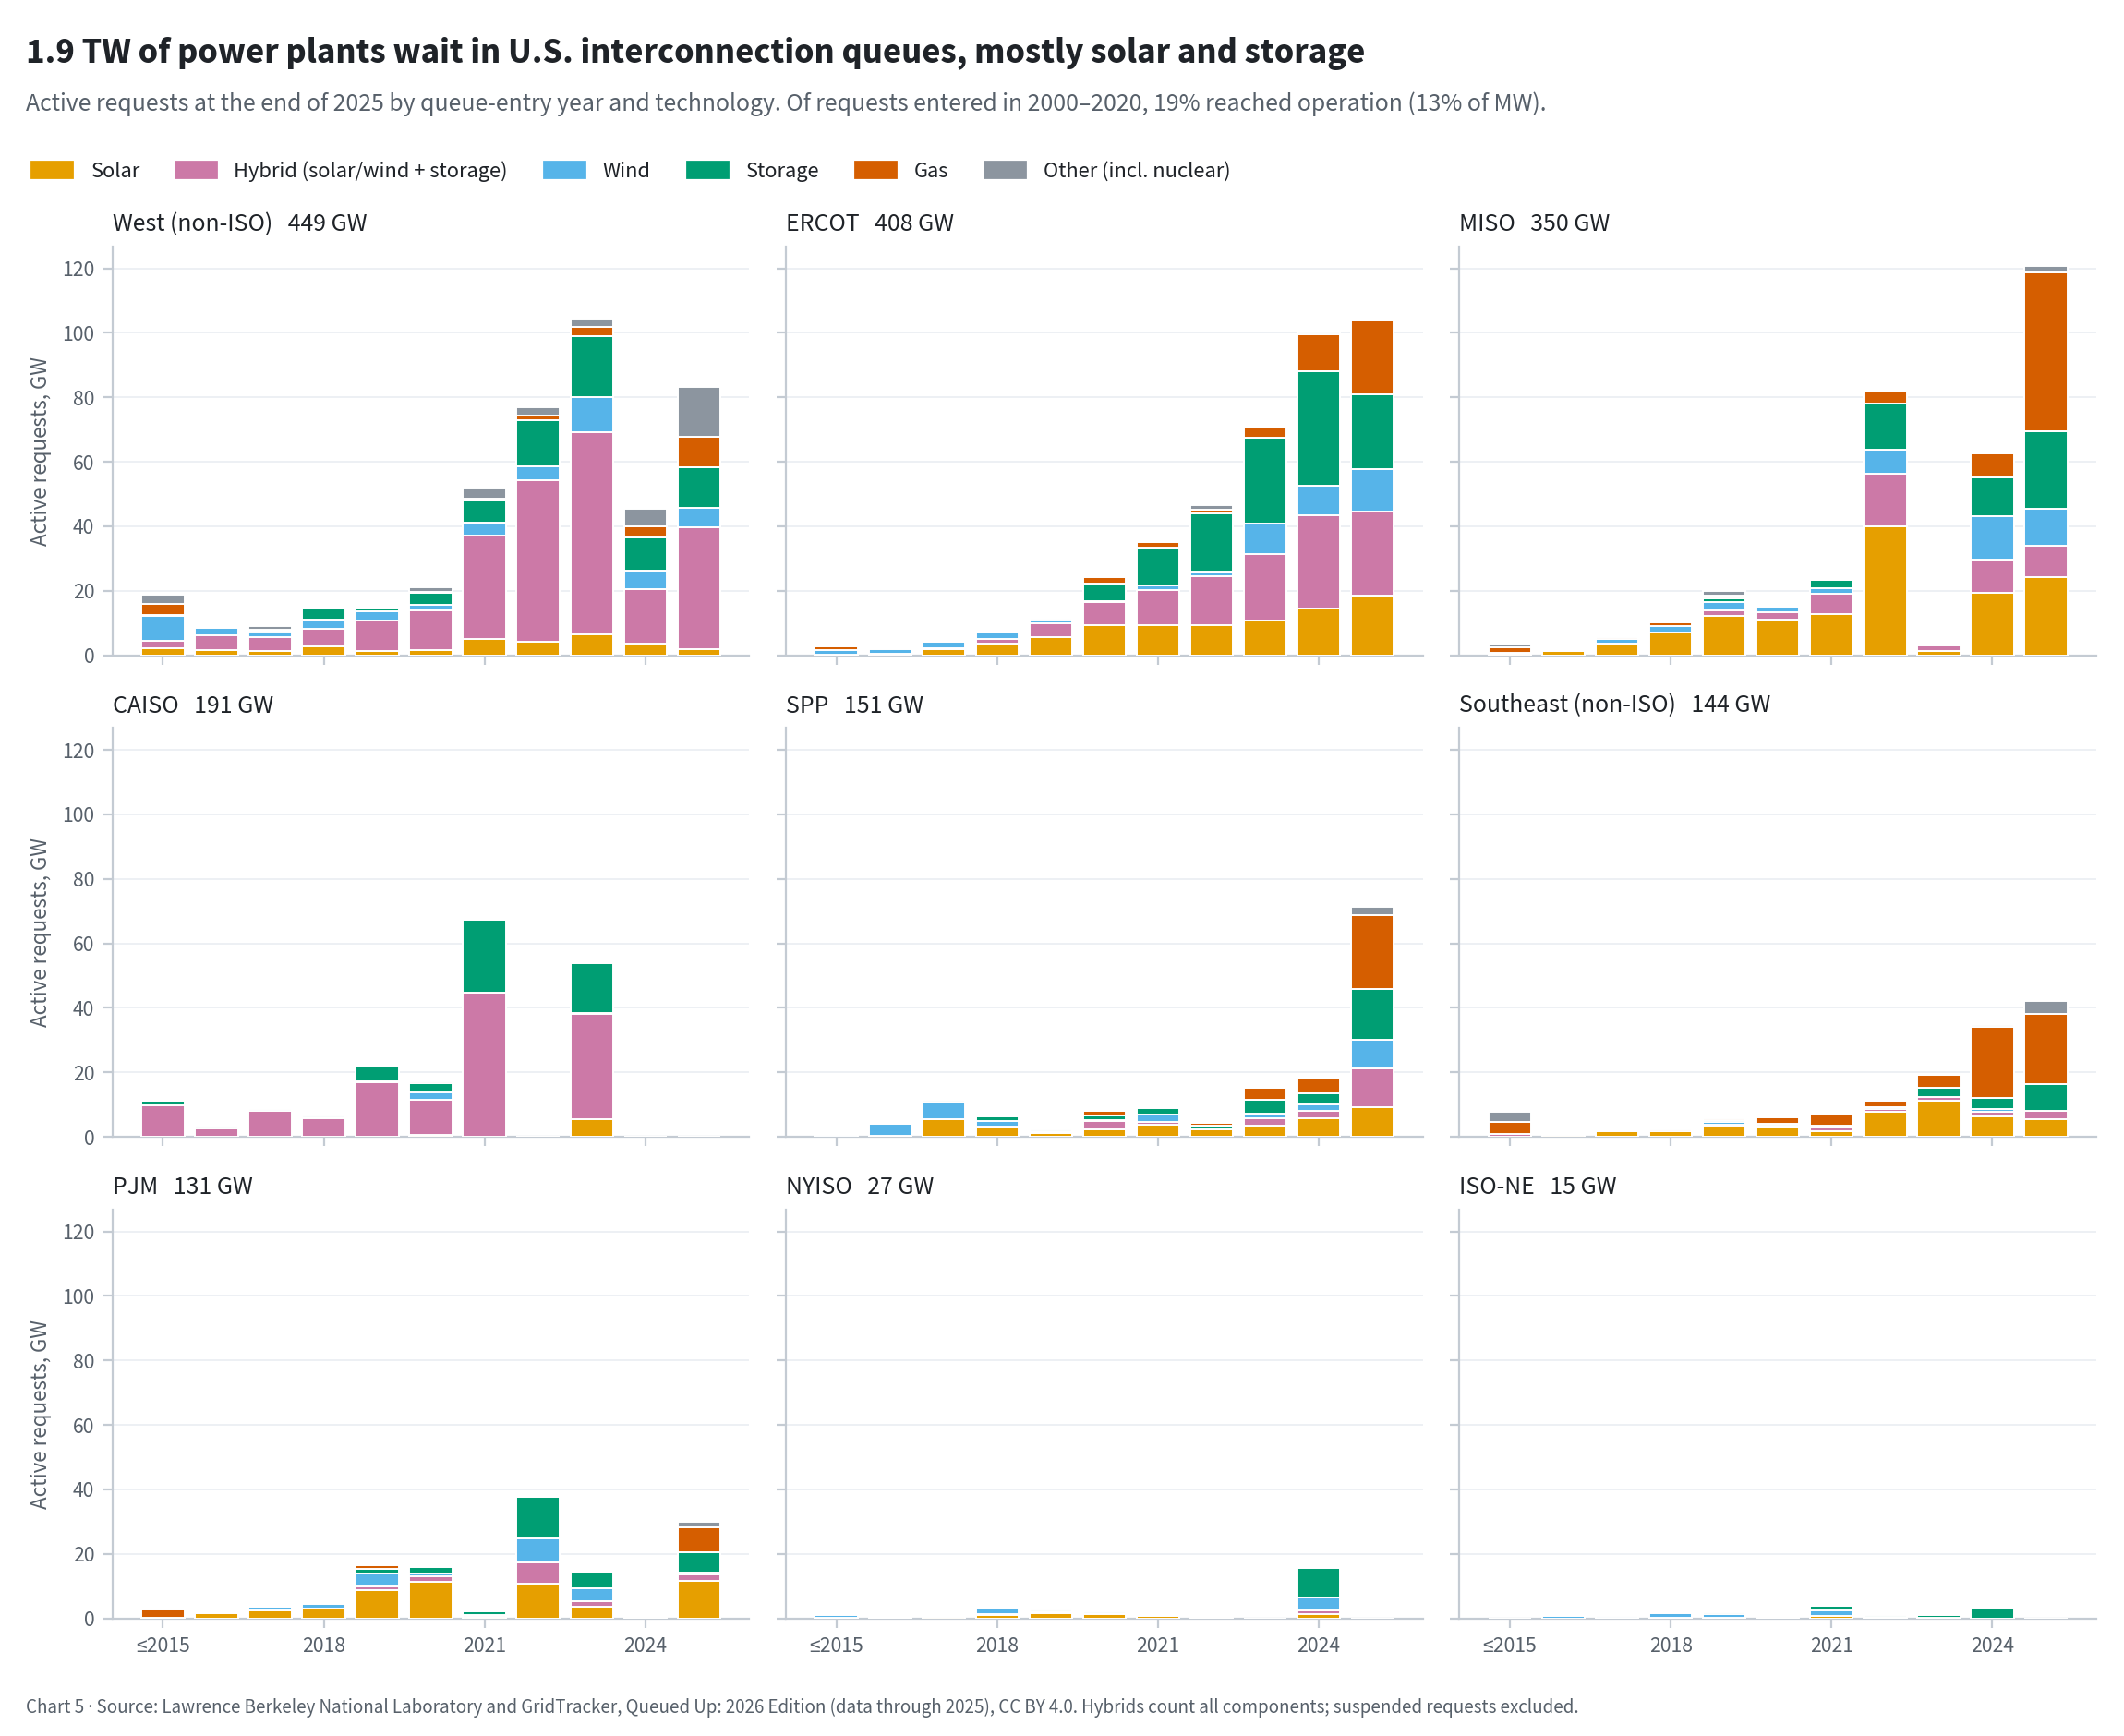

In [5]:
# Final themed figure (Prompt 16): light + dark, PNG + SVG in report/figures/
from IPython.display import Image
from glg.viz import figures as F
F.main(['chart5_queue_backlog'])
Image(filename=str(F.FIGURES_DIR / 'chart5_queue_backlog.png'), width=900)